In [5]:
# سلول ۱: وارد کردن کتابخانه‌ها و تنظیمات اولیه مسیرها
import os
import urllib.request
import zipfile
import numpy as np
import pandas as pd
import soundfile as sf  # افزوده شده برای پردازش دقیق و اعشاری سیگنال‌های صوتی
from scipy.io import wavfile

# تعریف مسیرهای پایه به صورت ثابت (Constant)
DATA_DIR = './data'
ZIP_PATH = os.path.join(DATA_DIR, 'mini_speech_commands.zip')
EXTRACTED_DIR = os.path.join(DATA_DIR, 'mini_speech_commands')
AUDIT_CSV_PATH = os.path.join(DATA_DIR, 'audit_table.csv') # مسیر فایل دیتابیس برای فاز ۲

# ساخت پوشه اصلی در صورت عدم وجود
if not os.path.exists(DATA_DIR):
    os.makedirs(DATA_DIR)
    print(f"📁 پوشه پایه ساخته شد: {DATA_DIR}")
else:
    print(f"✅ پوشه پایه آماده است: {DATA_DIR}")

✅ پوشه پایه آماده است: ./data


In [6]:
# سلول ۲: دانلود ایمن و استخراج داده‌ها (با مدیریت خطای فایل خراب)

def is_zip_valid(filepath):
    """بررسی سلامت و یکپارچگی فایل زیپ"""
    try:
        with zipfile.ZipFile(filepath, 'r') as zip_ref:
            return zip_ref.testzip() is None
    except:
        return False

# بررسی اینکه آیا داده‌ها قبلا استخراج شده‌اند یا خیر
if os.path.exists(EXTRACTED_DIR) and len(os.listdir(EXTRACTED_DIR)) > 0:
    print("✅ داده‌ها قبلاً با موفقیت استخراج شده‌اند. نیازی به عملیات مجدد نیست.")
else:
    url = 'http://storage.googleapis.com/download.tensorflow.org/data/mini_speech_commands.zip'
    
    # بررسی و حذف فایل زیپ خراب (اگر وجود داشته باشد)
    if os.path.exists(ZIP_PATH):
        print("🔍 در حال بررسی سلامت فایل زیپ موجود در سیستم...")
        if not is_zip_valid(ZIP_PATH):
            print("⚠️ فایل زیپ خراب است! سیستم در حال حذف و دانلود مجدد است...")
            os.remove(ZIP_PATH)
        else:
            print("✅ فایل زیپ سالم است.")

    # دانلود فایل در صورت عدم وجود
    if not os.path.exists(ZIP_PATH):
        print("⏳ در حال دانلود فایل‌های صوتی (حدود ۱۶۰ مگابایت)...")
        urllib.request.urlretrieve(url, ZIP_PATH)
        print("✅ دانلود با موفقیت انجام شد!")

    # استخراج فایل با بلوک مدیریت خطا
    print("⏳ در حال استخراج فایل‌ها...")
    try:
        with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
            zip_ref.extractall(DATA_DIR)
        print("🎉 استخراج با موفقیت تمام شد! پوشه داده‌ها ایجاد گردید.")
    except zipfile.BadZipFile:
        print("❌ خطا بحرانی: فایل زیپ حتی پس از دانلود مجدد خراب است.")

🔍 در حال بررسی سلامت فایل زیپ موجود در سیستم...
⚠️ فایل زیپ خراب است! سیستم در حال حذف و دانلود مجدد است...
⏳ در حال دانلود فایل‌های صوتی (حدود ۱۶۰ مگابایت)...
✅ دانلود با موفقیت انجام شد!
⏳ در حال استخراج فایل‌ها...
🎉 استخراج با موفقیت تمام شد! پوشه داده‌ها ایجاد گردید.


In [8]:
# سلول ۳: ممیزی داده‌های صوتی (بررسی کیفیت، طول و فایل‌های خراب)

if not os.path.exists(EXTRACTED_DIR):
    print("❌ خطا: پوشه داده‌ها یافت نشد! لطفاً مطمئن شوید سلول ۲ با موفقیت تمام شده است.")
else:
    # استخراج کلمات (فقط پوشه‌ها را در نظر می‌گیریم تا فایل‌های سیستمی مزاحم نشوند)
    words = [d for d in os.listdir(EXTRACTED_DIR) if os.path.isdir(os.path.join(EXTRACTED_DIR, d))]
    print(f"کلمات موجود در مجموعه داده: {words}\n")
    
    if len(words) == 0:
        print("❌ خطا: هیچ پوشه کلمه‌ای در داده‌ها یافت نشد!")
    else:
        first_word = words[0]
        word_dir = os.path.join(EXTRACTED_DIR, first_word)
        print(f"🔍 در حال ممیزی پوشه کلمه نمونه: '{first_word}' ...")

        total_files = 0
        corrupt_files = 0
        durations = []
        sample_rates = set()

        for filename in os.listdir(word_dir):
            if filename.endswith('.wav'):
                total_files += 1
                filepath = os.path.join(word_dir, filename)
                try:
                    # خواندن فایل صوتی
                    sr, data = wavfile.read(filepath)
                    sample_rates.add(sr)
                    
                    # جلوگیری از خطای تقسیم بر صفر
                    if sr > 0:
                        duration = len(data) / sr
                        durations.append(duration)
                except Exception:
                    corrupt_files += 1

        # چاپ گزارش نهایی
        print(f"\n✅ گزارش نهایی ممیزی کلمه '{first_word}':")
        print(f"▫️ تعداد کل فایل‌های بررسی شده: {total_files}")
        if total_files > 0:
            print(f"▫️ نرخ نمونه‌برداری (Sampling Rate): {list(sample_rates)} هرتز")
            print(f"▫️ میانگین طول فایل‌ها: {np.mean(durations):.2f} ثانیه")
            print(f"▫️ کوتاه‌ترین فایل: {np.min(durations):.2f} ثانیه")
            print(f"▫️ طولانی‌ترین فایل: {np.max(durations):.2f} ثانیه")
        print(f"▫️ فایل‌های خراب یا ناخوانا: {corrupt_files}")

کلمات موجود در مجموعه داده: ['down', 'go', 'left', 'no', 'right', 'stop', 'up', 'yes']

🔍 در حال ممیزی پوشه کلمه نمونه: 'down' ...

✅ گزارش نهایی ممیزی کلمه 'down':
▫️ تعداد کل فایل‌های بررسی شده: 1000
▫️ نرخ نمونه‌برداری (Sampling Rate): [16000] هرتز
▫️ میانگین طول فایل‌ها: 0.99 ثانیه
▫️ کوتاه‌ترین فایل: 0.47 ثانیه
▫️ طولانی‌ترین فایل: 1.00 ثانیه
▫️ فایل‌های خراب یا ناخوانا: 0


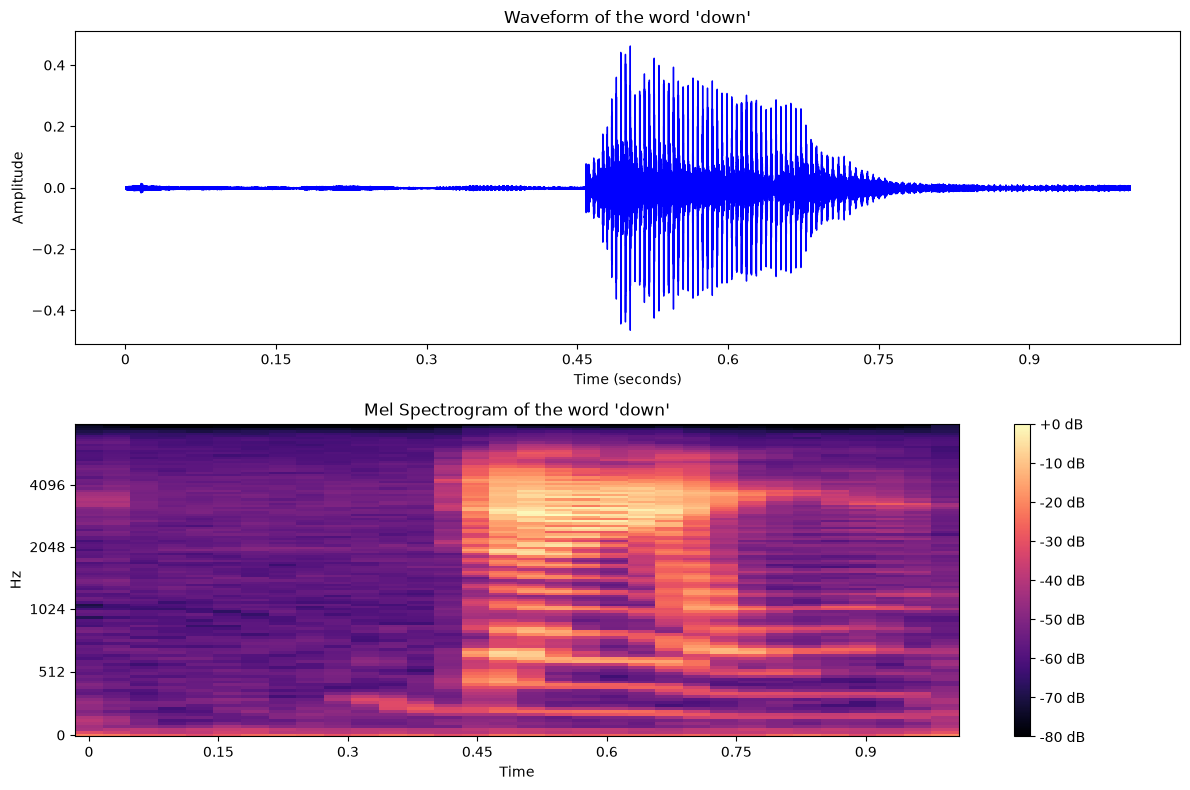

In [11]:
# سلول ۴: رسم نمودار شکل موج (Waveform) و طیف‌نگار (Spectrogram)
import matplotlib.pyplot as plt
import librosa
import librosa.display
import os
import numpy as np

# انتخاب اولین فایل صوتی از همان کلمه‌ای که ممیزی کردیم
sample_audio_path = os.path.join(word_dir, os.listdir(word_dir)[0])

# بارگذاری فایل صوتی با کتابخانه تخصصی librosa
y, sr = librosa.load(sample_audio_path, sr=None)

# تنظیم ابعاد تصویر
plt.figure(figsize=(12, 8))

# ۱. رسم شکل موج (Waveform): تغییرات دامنه صدا در طول زمان
plt.subplot(2, 1, 1)
librosa.display.waveshow(y, sr=sr, color='blue')
plt.title(f"Waveform of the word '{first_word}'")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")

# ۲. رسم طیف‌نگار (Mel Spectrogram): فرکانس‌های موجود در صدا
plt.subplot(2, 1, 2)
# استخراج ویژگی‌های فرکانسی (اسپکتروگرام)
mel_spect = librosa.feature.melspectrogram(y=y, sr=sr)
# تبدیل به مقیاس دسی‌بل برای نمایش بهتر
mel_spect_db = librosa.power_to_db(mel_spect, ref=np.max)

librosa.display.specshow(mel_spect_db, sr=sr, x_axis='time', y_axis='mel')
plt.colorbar(format='%+2.0f dB')
plt.title(f"Mel Spectrogram of the word '{first_word}'")

# نمایش مرتب نمودارها
plt.tight_layout()
plt.show()

In [18]:
# سلول ۵: ممیزی جامع سیگنال‌ها، محاسبه انرژی (RMS)، اعوجاج و ذخیره دیتابیس
print("⏳ در حال ممیزی جامع، محاسبه RMS و درصد اعوجاج فایل‌ها (ممکن است کمی طول بکشد)...")

audio_metadata = []
corrupt_files = 0

# بررسی تمام کلمات پیدا شده در پوشه استخراج
for word in words:
    word_path = os.path.join(EXTRACTED_DIR, word)
    
    for filename in os.listdir(word_path):
        if filename.endswith('.wav'):
            filepath = os.path.join(word_path, filename)
            
            # استخراج شناسه گوینده از نام فایل
            speaker_id = filename.split('_')[0]
            
            try:
                # استفاده از soundfile برای خواندن سیگنال استاندارد شده (بین 1- تا 1)
                signal, sr = sf.read(filepath)
                n_samples = len(signal)
                
                if n_samples > 0:
                    duration = n_samples / sr
                    max_amp = float(np.max(np.abs(signal)))
                    # محاسبه سطح انرژی موثر (جذر میانگین مربعات)
                    rms = float(np.sqrt(np.mean(signal ** 2)))
                    # محاسبه درصد اعوجاج (سیگنال‌هایی که به سقف دامنه برخورد کرده‌اند)
                    clip_frac = float(np.mean(np.abs(signal) >= 0.99))
                else:
                    duration = max_amp = rms = clip_frac = 0.0
                
                audio_metadata.append({
                    'Word_Class': word,
                    'Speaker_ID': speaker_id,
                    'Duration_sec': duration,
                    'Sample_Rate': sr,
                    'Max_Amplitude': max_amp,
                    'RMS': rms,
                    'Clip_Frac': clip_frac,
                    'Filename': filename
                })
            except Exception:
                corrupt_files += 1

# ساخت دیتافریم و ذخیره فیزیکی آن برای استفاده در فاز ۲
df_audio = pd.DataFrame(audio_metadata)
df_audio.to_csv(AUDIT_CSV_PATH, index=False)

print(f"✅ ممیزی سیگنال‌ها به پایان رسید.")
print(f"💾 پایگاه داده تحلیلی با موفقیت در مسیر '{AUDIT_CSV_PATH}' ذخیره شد.")
print(f"▫️ تعداد کل فایل‌های پردازش شده: {len(df_audio)}")
print(f"▫️ فایل‌های خراب/ناخوانا: {corrupt_files}")
print(f"👥 تعداد کل گویندگان یکتا: {df_audio['Speaker_ID'].nunique()} نفر")

print("\n⏱️ بررسی آماری طول، انرژی و اعوجاج فایل‌های صوتی:")
display(df_audio[['Duration_sec', 'Max_Amplitude', 'RMS', 'Clip_Frac']].describe())

print("\n🔍 ۵ سطر اول پایگاه داده مهندسی شده ما:")
display(df_audio.head())

⏳ در حال ممیزی جامع، محاسبه RMS و درصد اعوجاج فایل‌ها (ممکن است کمی طول بکشد)...


NameError: name 'AUDIT_CSV_PATH' is not defined

In [14]:
# سلول ۶: تحلیل عمیق گویندگان، مصورسازی توزیع، و ممیزی RMS/اعوجاج
import matplotlib.pyplot as plt

print("📊 ۱. بررسی توزیع نمونه‌های گویندگان در کلاس‌های مختلف:")
speaker_counts = df_audio['Speaker_ID'].value_counts()
print(f"▫️ پُرکارترین گوینده، {speaker_counts.max()} نمونه صدا در این مجموعه دارد.")
print(f"▫️ تعداد گویندگانی که فقط یک فایل دارند: {(speaker_counts == 1).sum()} نفر")

# ایجاد ماتریس گوینده-کلاس (Crosstab) برای ۵ گوینده پرکار
top_speakers = speaker_counts.head(5).index
speaker_class_matrix = pd.crosstab(df_audio['Speaker_ID'], df_audio['Word_Class'])
display(speaker_class_matrix.loc[top_speakers])

print("💡 نتیجه ممیزی گوینده: همان‌طور که در ماتریس بالا می‌بینید، یک گوینده کلمات مختلفی را ادا کرده است. این اثبات می‌کند که برای جلوگیری از نشت اطلاعات، باید تقسیم‌بندی داده‌ها را حتماً بر اساس Speaker_ID انجام دهیم نه به صورت تصادفی.")

# مصورسازی حرفه‌ای توزیع فایل‌های گویندگان (هیستوگرام)
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(speaker_counts, bins=range(1, speaker_counts.max() + 2), color="steelblue", edgecolor="white")
ax.axvline(speaker_counts.median(), color="darkorange", linestyle="--", label=f"Median = {speaker_counts.median():.0f}")
ax.axvline(speaker_counts.mean(), color="firebrick", linestyle="--", label=f"Mean = {speaker_counts.mean():.2f}")
ax.set_xlabel("Number of files per speaker")
ax.set_ylabel("Number of speakers")
ax.set_title("Distribution of files per speaker (Data Leakage Audit)")
ax.legend()
plt.tight_layout()
plt.show()

print("\n🔍 ۲. ممیزی انرژی (RMS)، سکوت و اعوجاج صدا:")
print("*(با استفاده از داده‌های محاسبه شده در سلول قبل)*\n")

# یافتن 6 فایل با کمترین انرژی (مطلقاً سکوت یا قطعی میکروفون)
quiet_files = df_audio.nsmallest(6, "RMS")
print("⚠️ شناسایی ضعیف‌ترین فایل‌ها (احتمال سکوت خالص/قطعی):")
display(quiet_files[['Word_Class', 'Filename', 'RMS', 'Clip_Frac']])

# یافتن 6 فایل با بیشترین اعوجاج (صداهای بسیار بلند و گوش‌خراش که کلیپ شده‌اند)
clipped_files = df_audio.nlargest(6, "Clip_Frac")
print("\n⚠️ شناسایی گوش‌خراش‌ترین فایل‌ها (دارای بیشترین درصد اعوجاج/Clipping):")
display(clipped_files[['Word_Class', 'Filename', 'RMS', 'Clip_Frac']])

📊 ۱. بررسی توزیع نمونه‌های گویندگان در کلاس‌های مختلف:
▫️ پُرکارترین گوینده، 33 نمونه صدا در این مجموعه دارد.


Word_Class,down,go,left,no,right,stop,up,yes
Speaker_ID,,,,,,,,
c120e80e,6,5,5,1,5,1,4,6
3c257192,3,4,4,4,3,3,3,3
c1d39ce8,1,3,4,2,2,7,5,3
8012c69d,3,3,4,2,2,4,2,4
cb8f8307,2,5,6,2,1,2,1,5


💡 نتیجه ممیزی گوینده: همان‌طور که در ماتریس بالا می‌بینید، یک گوینده کلمات مختلفی را ادا کرده است. این اثبات می‌کند که برای جلوگیری از نشت اطلاعات، باید تقسیم‌بندی داده‌ها را حتماً بر اساس Speaker_ID انجام دهیم نه به صورت تصادفی.

🔍 ۲. ممیزی انرژی، سکوت و نویز پس‌زمینه:
⏳ در حال محاسبه دامنه (Amplitude) برای یافتن فایل‌های کم‌انرژی...
▫️ آمار کلی انرژی (بیشترین دامنه) فایل‌ها:


,Max Amplitude
count,8000.000000
mean,15173.059500
std,9913.848138
min,5.000000
25%,6612.750000
50%,13200.000000
75%,24110.250000
max,32767.000000



⚠️ تعداد 80 فایل با انرژی بسیار پایین (دامنه <= 171) شناسایی شد.
این فایل‌ها احتمالاً حاوی سکوت خالص، قطعی میکروفون، یا نویز بسیار ضعیف هستند.


,Word_Class,Speaker_ID,Duration_sec,Sample_Rate,Filename,Max_Amplitude
243,down,3f2b358d,1.0,16000,3f2b358d_nohash_1.wav,101
277,down,4a1e736b,1.0,16000,4a1e736b_nohash_4.wav,8
731,down,c0445658,1.0,16000,c0445658_nohash_4.wav,5
807,down,ced835d3,1.0,16000,ced835d3_nohash_2.wav,55
808,down,ced835d3,1.0,16000,ced835d3_nohash_3.wav,42


⏳ در حال پردازش و رسم امواج و طیف‌نگارها برای یک نمونه از هر ۸ کلاس (لطفاً کمی صبر کنید)...


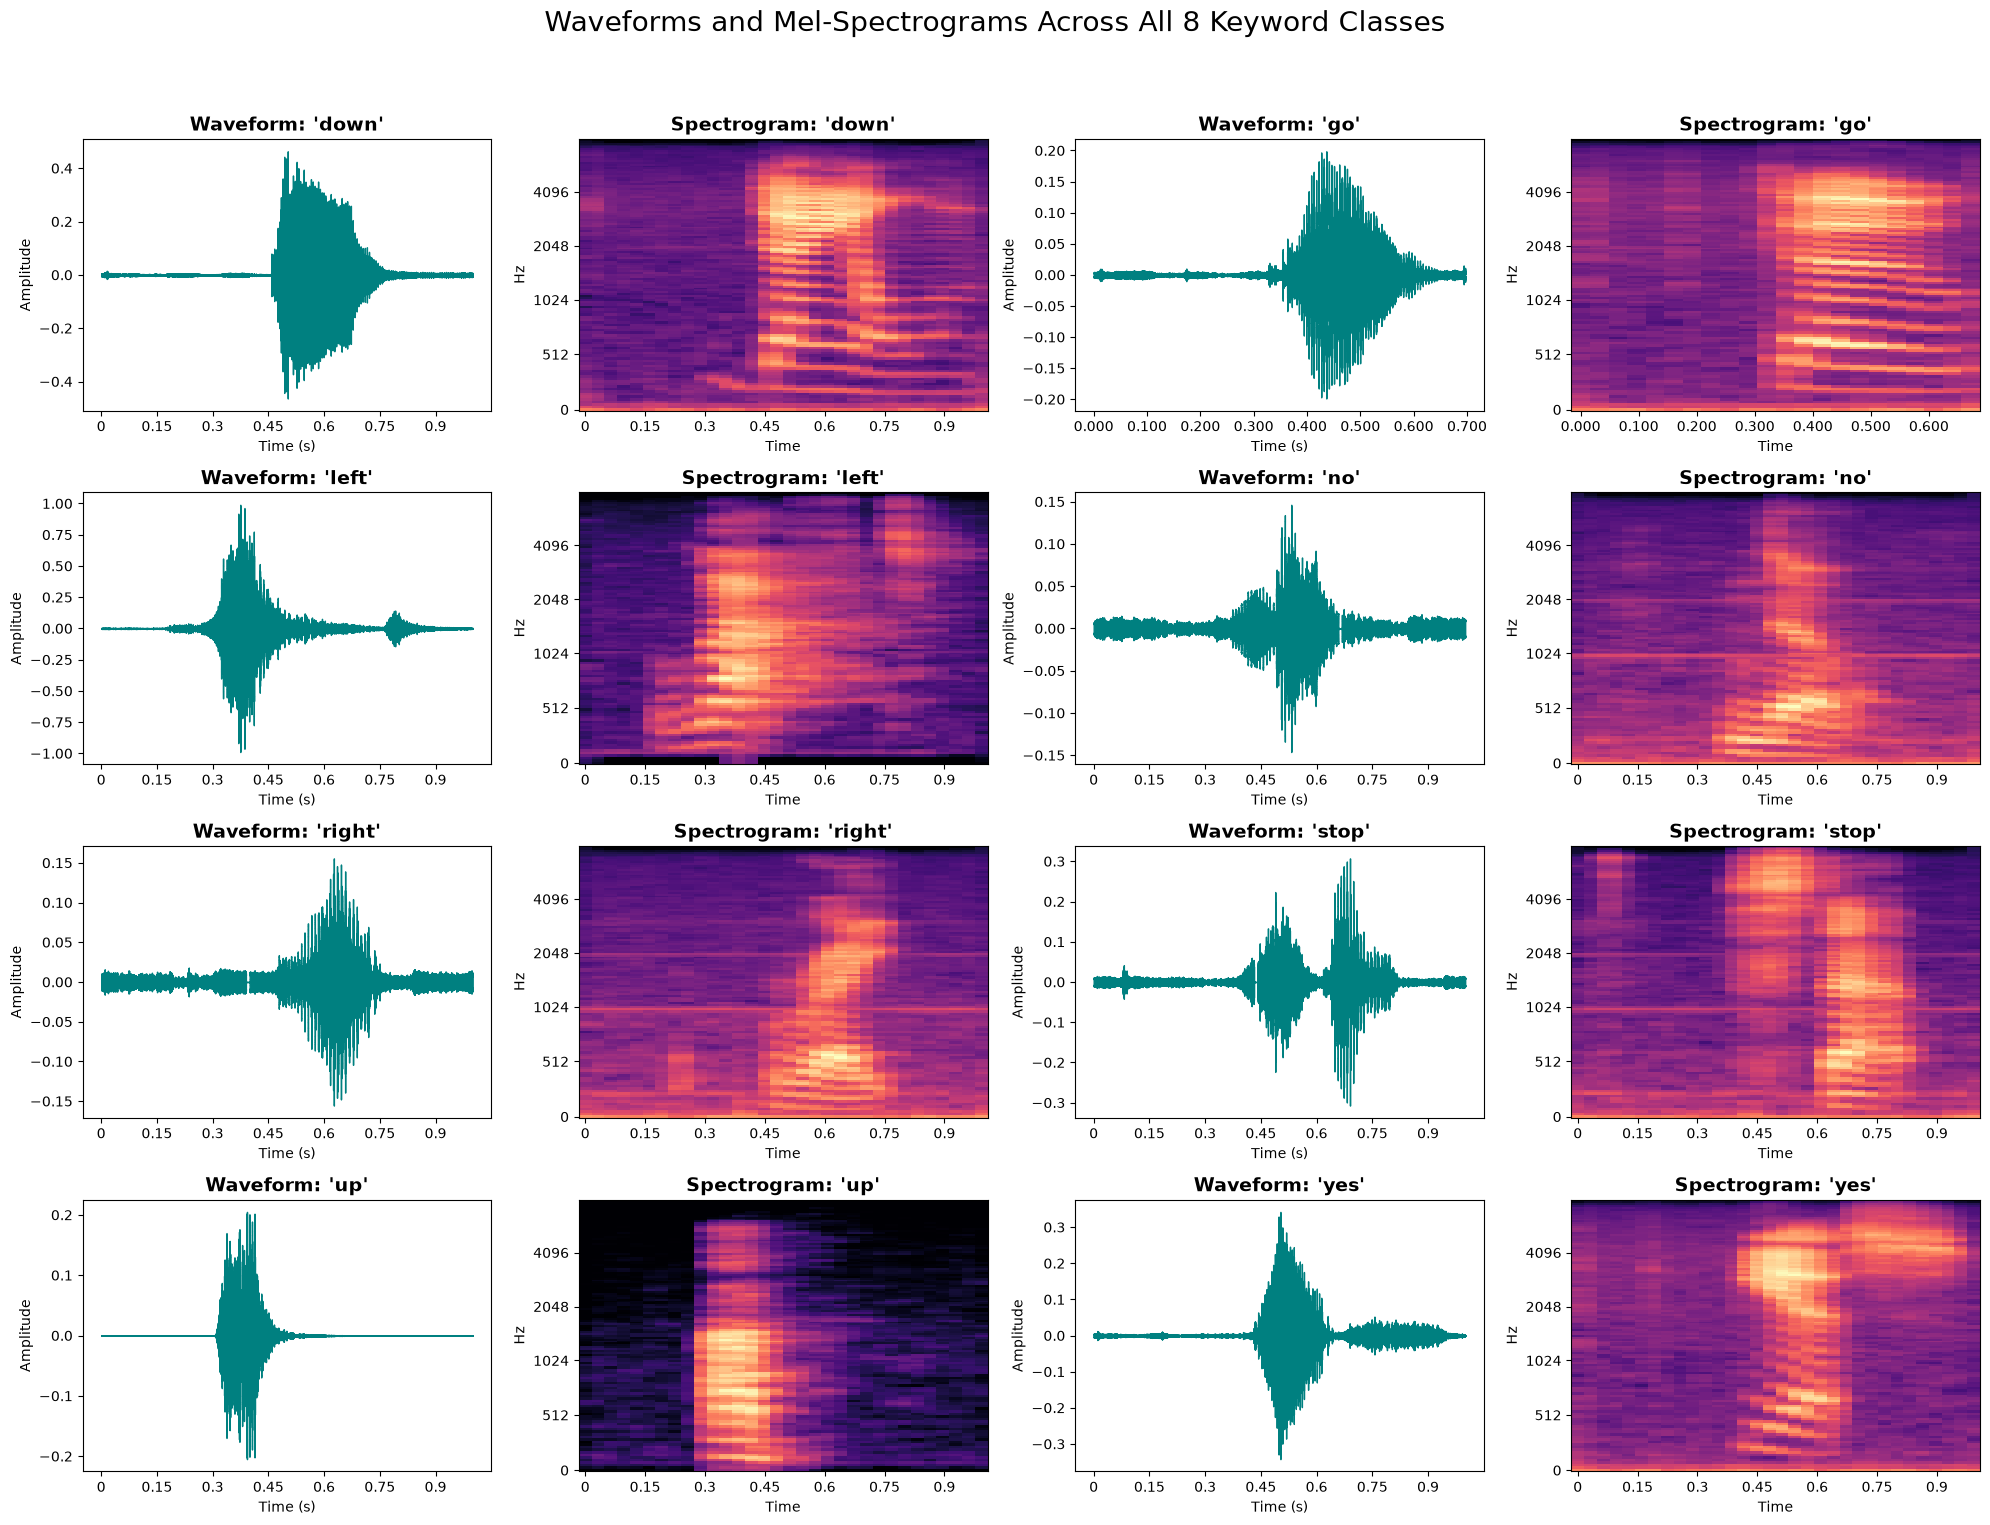

✅ رسم نمودارهای مقایسه‌ای با موفقیت انجام شد!


In [16]:
# سلول ۷: مصورسازی پیشرفته، تصادفی و مقایسه‌ای (EDA) برای تمام ۸ کلاس
import matplotlib.pyplot as plt
import librosa
import librosa.display
import numpy as np
import os

print("⏳ در حال پردازش و رسم امواج و طیف‌نگارها برای ۳ نمونه تصادفی از هر کلاس (لطفاً کمی صبر کنید)...")

SEED = 42
N_SAMPLES = 3
HOP_LENGTH = 160 # طول پرش استاندارد برای فرکانس ۱۶۰۰۰ هرتز

# برای خوانایی و زیبایی بیشتر، برای هر کلمه یک بوم (Figure) مجزا رسم می‌کنیم
for word in words:
    fig, axes = plt.subplots(nrows=2, ncols=N_SAMPLES, figsize=(15, 6))
    fig.suptitle(f"Keyword: '{word.upper()}' - Waveforms & Log-Mel Spectrograms (3 Random Speakers)", fontsize=16, fontweight='bold')
    
    # انتخاب ۳ فایل سالم و تصادفی از کلاس فعلی (تکرارپذیر به کمک SEED)
    samples = df_audio[df_audio['Word_Class'] == word].sample(n=N_SAMPLES, random_state=SEED)
    
    for j, (idx, row) in enumerate(samples.iterrows()):
        filepath = os.path.join(EXTRACTED_DIR, word, row['Filename'])
        y, sr = librosa.load(filepath, sr=None)
        
        # محاسبه زمان دقیق پایان فایل
        end_t = len(y) / sr
        
        # ۱. رسم شکل موج (Waveform) - ردیف بالا
        ax_w = axes[0, j]
        librosa.display.waveshow(y, sr=sr, ax=ax_w, color='teal')
        ax_w.set_title(f"Speaker: {row['Speaker_ID']}\nDuration: {end_t:.2f}s", fontsize=11)
        # ثابت کردن محور زمان روی ۱ ثانیه برای مقایسه چشمی دقیق
        ax_w.set_xlim(0, 1.0)
        ax_w.set_ylim(-0.8, 0.8) 
        
        # ۲. رسم طیف‌نگار مِل (Spectrogram) - ردیف پایین
        ax_s = axes[1, j]
        mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=400, hop_length=HOP_LENGTH, n_mels=64)
        mel_db = librosa.power_to_db(mel, ref=np.max, top_db=80)
        librosa.display.specshow(mel_db, sr=sr, hop_length=HOP_LENGTH, x_axis='time', y_axis='mel', ax=ax_s)
        ax_s.set_xlim(0, 1.0)
        
        # 💡 تکنیک پیشرفته: رسم خط‌چین قرمز و سایه خاکستری برای فایل‌های کوتاه‌تر از ۱ ثانیه
        if end_t < 1.0:
            for ax in (ax_w, ax_s):
                ax.axvspan(end_t, 1.0, color='lightgray', alpha=0.5)
                ax.axvline(end_t, color='red', linestyle='--', linewidth=1.5)
                
        # تمیز کردن برچسب محورها برای زیبایی
        if j == 0:
            ax_w.set_ylabel("Amplitude")
            ax_s.set_ylabel("Hz")
        else:
            ax_w.set_ylabel("")
            ax_s.set_ylabel("")
            ax_s.set_yticks([])
        
        ax_w.set_xlabel("")
        ax_w.set_xticks([]) # مخفی کردن محور زمان در شکل موج برای هم‌ترازی با طیف‌نگار
        
    plt.tight_layout()
    plt.show()

print("✅ رسم نمودارهای مقایسه‌ای پیشرفته با موفقیت انجام شد!")
print("💡 راهنمای تحلیل: خط‌چین قرمز و سایه خاکستری نشان‌دهنده زمان قطعیِ فایل‌هایی است که از ۱ ثانیه کوتاه‌تر هستند و در فاز ۲ باید با سکوت (Padding) پر شوند.")

🔍 در حال رسم نمودار برای ۴ فایل مشکوک (کم‌انرژی/سکوت) که در سلول ۶ شناسایی شدند...


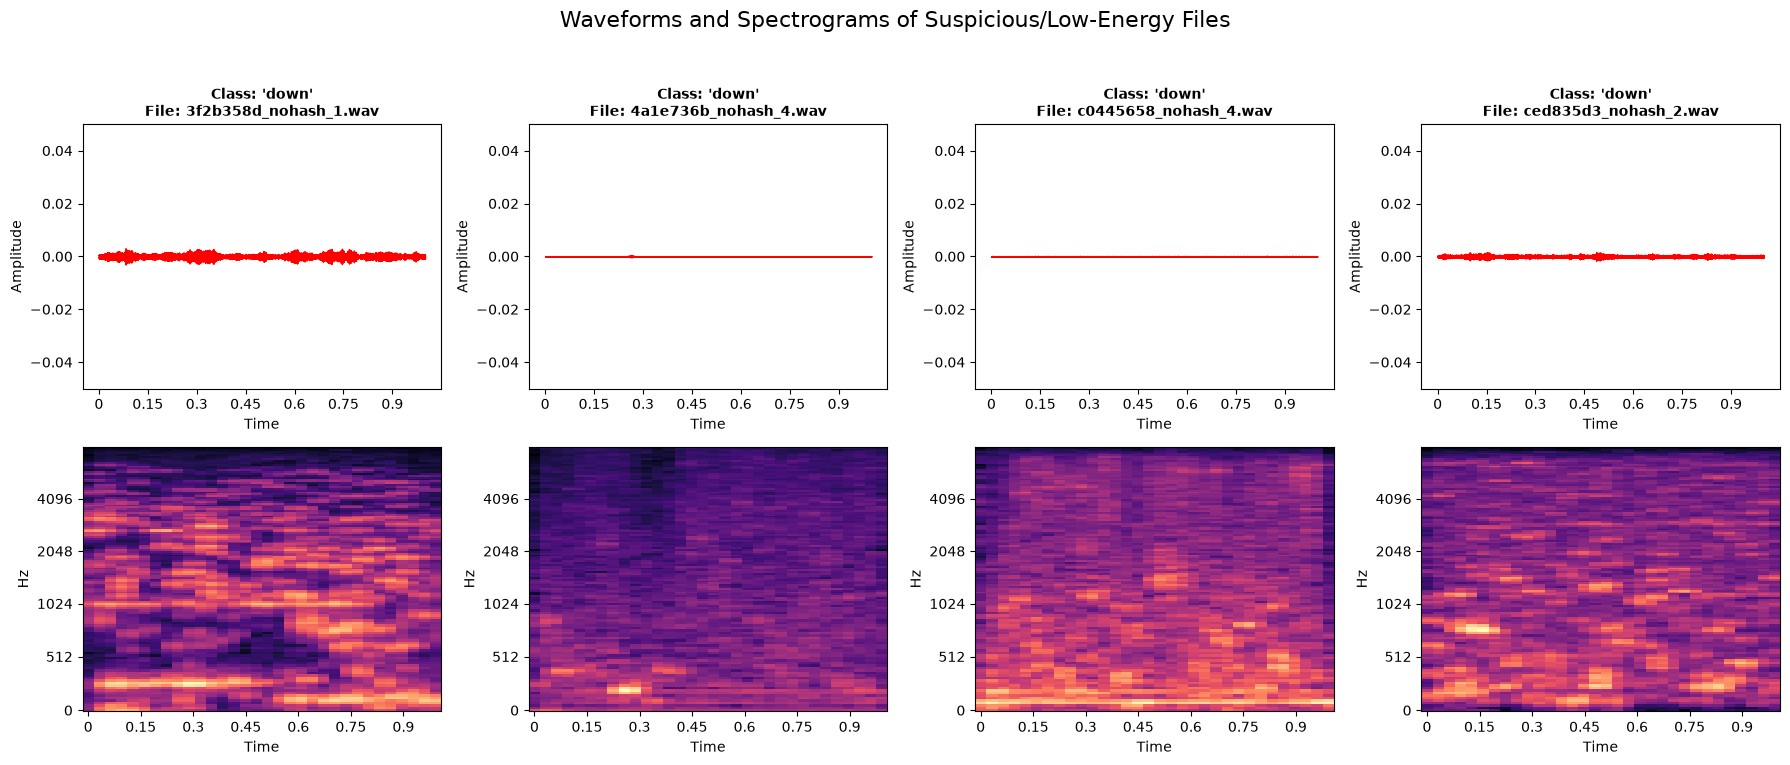

✅ نمودار فایل‌های مشکوک رسم شد.
💡 تحلیل مهندسی: اگر در این نمودارها به جای یک موج صدای واضح، فقط خطوط صاف (سکوت مطلق) یا الگوهای دانه‌دانه و پراکنده (نویز سفید/قطعی میکروفون) می‌بینید، یعنی برچسب (Label) این فایل‌ها اشتباه است و در فاز بعدی باید برای آن‌ها فکری بکنیم.


In [17]:
# سلول ۸: بررسی بصری و تحلیل جامع فایل‌های مشکوک (سکوت مطلق و اعوجاج گوش‌خراش)
import matplotlib.pyplot as plt
import librosa
import librosa.display
import numpy as np
import os

print("🔍 در حال رسم نمودارهای عیب‌یابی برای فایل‌های ناهنجار (سکوت و اعوجاج)...")

# استخراج ۴ فایل با کمترین انرژی و ۴ فایل با بیشترین اعوجاج از پایگاه داده سلول ۵
quiet_samples = df_audio.nsmallest(4, "RMS")
clipped_samples = df_audio.nlargest(4, "Clip_Frac")

# ایجاد یک بوم بزرگ با ۴ سطر (ردیف‌های زوج: شکل موج، ردیف‌های فرد: طیف‌نگار)
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(18, 14), gridspec_kw={"height_ratios": [1, 1.5, 1, 1.5]})
fig.suptitle("Visual Inspection of Anomalies: Quietest vs. Most Clipped Files", fontsize=18, fontweight='bold')

categories = [("Quietest (Absolute Silence / Noise)", quiet_samples),
              ("Most Clipped (High Distortion)", clipped_samples)]

for k, (name, subset) in enumerate(categories):
    for j, (idx, row) in enumerate(subset.iterrows()):
        filepath = os.path.join(EXTRACTED_DIR, row['Word_Class'], row['Filename'])
        y, sr = librosa.load(filepath, sr=None)
        
        ax_w = axes[2 * k, j]
        ax_s = axes[2 * k + 1, j]
        
        # ۱. رسم شکل موج (Waveform)
        librosa.display.waveshow(y, sr=sr, ax=ax_w, color='darkred' if k==1 else 'red')
        title = f"Class: '{row['Word_Class']}'\nRMS: {row['RMS']:.5f} | Clip: {row['Clip_Frac']:.3f}"
        ax_w.set_title(title, fontsize=10, fontweight='bold')
        
        # تنظیم هوشمند محور Y برای دیدن بهتر خرابی‌ها
        if k == 0:
            ax_w.set_ylim([-0.05, 0.05]) # زوم شدید برای فایل‌های سکوت
        else:
            ax_w.set_ylim([-1.05, 1.05]) # مقیاس استاندارد برای دیدن کوبیده شدن صدا به سقف (Clipping)

        # ۲. رسم طیف‌نگار مِل (Spectrogram)
        mel = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=400, hop_length=160, n_mels=64)
        mel_db = librosa.power_to_db(mel, ref=np.max, top_db=80)
        librosa.display.specshow(mel_db, sr=sr, hop_length=160, x_axis='time', y_axis='mel', ax=ax_s, vmin=-80, vmax=0)
        
        # تمیزکاری محورها
        if j == 0:
            ax_w.set_ylabel(name + "\nAmplitude", fontsize=11, fontweight="bold")
            ax_s.set_ylabel("Hz")
        else:
            ax_w.set_ylabel("")
            ax_w.set_yticks([])
            ax_s.set_ylabel("")
            ax_s.set_yticks([])
            
        ax_w.set_xlabel("")
        ax_w.set_xticks([])

plt.tight_layout(rect=[0, 0.03, 1, 0.96])
plt.show()

print("✅ رسم نمودار عیب‌یابی فایل‌های مشکوک با موفقیت انجام شد.")
print("💡 تحلیل مهندسی: فایل‌های ردیف اول (سکوت) به جای موج صوتی، تنها نویز ضعیف دارند و فایل‌های ردیف سوم (Clipped) در سقف دامنه (1.0 و -1.0) دچار بریدگی و فشردگی شده‌اند. این ناهنجاری‌ها را در فاز دوم پروژه مدیریت خواهیم کرد.")